# Análisis del comportamiento y la fidelización de clientes en plataformas de comercio electrónico
### *Customer Behavior & Retention Analysis*

**Curso:** Programación II — Ciencia de Datos

**Integrantes:** Mafe · Artur · Wendy

**Fuente de datos:** [Ecommerce Customer Behavior Dataset – Kaggle](https://www.kaggle.com/datasets/srisyra02/ecommerce-customer-behavior-dataset)

---

**Pregunta central:** ¿Qué características y comportamientos de los clientes están relacionados con su permanencia o abandono de una plataforma de comercio electrónico?

**Objetivo general:** Analizar los patrones de comportamiento, interacción y transacciones de los clientes para identificar factores asociados con su fidelización y abandono.

**Preguntas guía:**
- ¿Qué tipo de clientes tienen mayor tendencia a abandonar la plataforma?
- ¿Los clientes que interactúan con mayor frecuencia permanecen más?
- ¿Existe relación entre la experiencia del cliente (servicio al cliente, carrito) y la fidelización?
- ¿Qué grupos de clientes generan mayor valor para la empresa?
- ¿Qué características tienen los clientes más comprometidos?

**Contenido del notebook**
1. Carga e inspección inicial de los datos
2. Manejo de datos faltantes
3. Identificación y tratamiento de outliers
4. Valores inconsistentes, texto y duplicados
5. Creación de variables
6. Filtrado y condiciones con Pandas (5 resultados)
7. Agrupación con `groupby` (5 resultados)
8. Visualizaciones (5 gráficos)
9. Conclusiones

## Instalación de librerías

> **Ejecutar solo la primera vez en cada computador.**
> La siguiente celda instala las librerías necesarias para el análisis (pandas, numpy, matplotlib y seaborn).
> Si las librerías ya están instaladas, esta celda se puede omitir.

In [206]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [207]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Carga e inspección inicial de los datos

In [208]:
datos = pd.read_csv("ecommerce-dataset.csv")
datos.head()

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14,27.4,6.0,50.6,3.0,9.0,94.72,34.0,46.40,2.0,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15,42.7,10.3,37.7,1.0,19.5,82.45,71.0,57.96,9.2,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10,24.8,1.6,70.9,1.0,9.1,165.52,11.0,12.24,11.5,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10,38.4,14.8,41.7,9.0,15.0,147.33,47.0,44.10,5.4,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29,51.4,NaN,19.1,9.0,32.5,141.30,73.0,25.20,5.5,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


### 1.1 Tamaño del conjunto de datos

In [209]:
filas, columnas = datos.shape
print(f"El conjunto de datos tiene {filas} registros (clientes) y {columnas} columnas (variables).")

El conjunto de datos tiene 50000 registros (clientes) y 25 columnas (variables).


### 1.2 Tipos de variables

In [210]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  str    
 2   Country                        50000 non-null  str    
 3   City                           50000 non-null  str    
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  int64  
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       47000 non-null  float64
 1

Además del tipo que asigna Pandas, clasificamos cada variable según su **naturaleza estadística** para comprobar los requisitos del proyecto:

In [211]:
categoricas = ["Gender", "Country", "City", "Signup_Quarter", "Churned"]

discretas = ["Login_Frequency", "Wishlist_Items", "Total_Purchases", "Days_Since_Last_Purchase",
             "Customer_Service_Calls", "Product_Reviews_Written", "Payment_Method_Diversity"]

continuas = ["Age", "Membership_Years", "Session_Duration_Avg", "Pages_Per_Session",
             "Cart_Abandonment_Rate", "Average_Order_Value", "Discount_Usage_Rate", "Returns_Rate",
             "Email_Open_Rate", "Social_Media_Engagement_Score", "Mobile_App_Usage",
             "Lifetime_Value", "Credit_Balance"]

print(f"Registros: {len(datos)}  (requisito: más de 1000)")
print(f"Variables categóricas: {len(categoricas)}  (requisito: más de 2) -> {categoricas}")
print(f"Variables numéricas discretas: {len(discretas)}  (requisito: más de 2)")
print(f"Variables numéricas continuas: {len(continuas)}  (requisito: más de 2)")

Registros: 50000  (requisito: más de 1000)
Variables categóricas: 5  (requisito: más de 2) -> ['Gender', 'Country', 'City', 'Signup_Quarter', 'Churned']
Variables numéricas discretas: 7  (requisito: más de 2)
Variables numéricas continuas: 13  (requisito: más de 2)


> **Conclusión:** El dataset cumple con todos los requisitos del proyecto: tiene **50.000 registros**, 5 variables categóricas (incluyendo `Churned`, que indica si el cliente abandonó: 1 = sí, 0 = no), 7 numéricas discretas y 13 numéricas continuas.
> Pandas lee muchas variables discretas como `float64` porque contienen valores faltantes (`NaN` es un número decimal); esto se corrige después de la limpieza.

### 1.3 Descripción estadística

In [212]:
datos.describe().round(2)

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned
count,47505.00,50000.00,50000.00,46601.00,47000.00,50000.00,46000.00,50000.00,50000.00,47000.00,46500.00,45509.00,47472.00,49832.00,46500.00,44000.00,45000.00,47500.00,50000.00,44500.00,50000.00
mean,37.80,2.98,11.62,27.66,8.74,57.08,4.30,13.11,123.12,29.79,42.00,6.68,20.94,5.68,2.85,29.36,19.37,2.35,1440.63,1966.23,0.29
std,11.83,2.06,7.81,10.87,3.78,16.28,3.19,7.02,175.57,29.70,21.37,6.14,14.25,2.68,2.33,20.57,9.42,1.11,907.25,1225.07,0.45
min,5.00,0.10,0.00,1.00,1.00,0.00,0.00,-13.00,26.38,0.00,0.24,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
25%,29.00,1.40,6.00,19.70,6.00,46.40,2.00,8.00,87.05,9.00,25.30,2.90,9.90,4.00,1.00,13.20,12.50,2.00,789.82,1049.00,0.00
50%,38.00,2.50,11.00,26.80,8.40,58.10,4.00,12.00,112.97,21.00,40.20,5.40,19.70,5.00,2.00,27.60,18.60,2.00,1243.42,1896.00,0.00
75%,46.00,4.00,17.00,34.70,11.20,68.70,6.00,17.00,144.44,41.00,57.00,9.10,30.40,7.00,4.00,43.10,25.50,3.00,1874.00,2791.00,1.00
max,200.00,10.00,46.00,75.60,24.10,143.74,28.00,128.70,9666.38,287.00,116.64,99.62,91.70,21.00,21.00,100.00,61.90,5.00,8987.24,7197.00,1.00


In [213]:
datos.describe(include=["object", "string"])

,Gender,Country,City,Signup_Quarter
count,50000,50000,50000,50000
unique,3,8,40,4
top,Female,USA,Houston,Q3
freq,25116,17384,3549,12558


> **Conclusión:** La descripción estadística ya muestra **valores sospechosos** que se tratarán más adelante:
> - `Age` tiene un mínimo de 5 años y un máximo de 200 años (edades imposibles para un cliente).
> - `Total_Purchases` tiene valores **negativos** (mínimo −13) y decimales, aunque el número de compras debe ser un entero positivo.
> - `Cart_Abandonment_Rate` y `Discount_Usage_Rate` superan el 100 %, lo cual no es posible en un porcentaje.
> - `Average_Order_Value` tiene una media (123) muy por encima de la mediana (113) y un máximo de 9.666, lo que indica valores extremos.

In [214]:
# Proporción de clientes que abandonaron vs. que permanecen
datos["Churned"].value_counts(normalize=True).mul(100).round(1)

Churned
0    71.1
1    28.9
Name: proportion, dtype: float64

> **Conclusión:** El **28,9 %** de los clientes abandonó la plataforma y el **71,1 %** permanece. Esta es la tasa de abandono de referencia con la que compararemos los distintos grupos de clientes.

---
## 2. Manejo de datos faltantes

In [215]:
faltantes = pd.DataFrame({
    "Nulos": datos.isnull().sum(),
    "Porcentaje (%)": (datos.isnull().sum() / len(datos) * 100).round(2)
})
faltantes[faltantes["Nulos"] > 0].sort_values("Nulos", ascending=False)

,Nulos,Porcentaje (%)
Social_Media_Engagement_Score,6000,12.00
Credit_Balance,5500,11.00
Mobile_App_Usage,5000,10.00
Returns_Rate,4491,8.98
Wishlist_Items,4000,8.00
Discount_Usage_Rate,3500,7.00
Product_Reviews_Written,3500,7.00
Session_Duration_Avg,3399,6.80
Pages_Per_Session,3000,6.00
Days_Since_Last_Purchase,3000,6.00


In [216]:
filas_con_nulos = datos.isnull().any(axis=1).sum()
print(f"Filas con al menos un valor faltante: {filas_con_nulos} ({filas_con_nulos / len(datos) * 100:.1f} % del total)")

Filas con al menos un valor faltante: 32017 (64.0 % del total)


### 2.1 Mapa de calor de valores faltantes (antes)

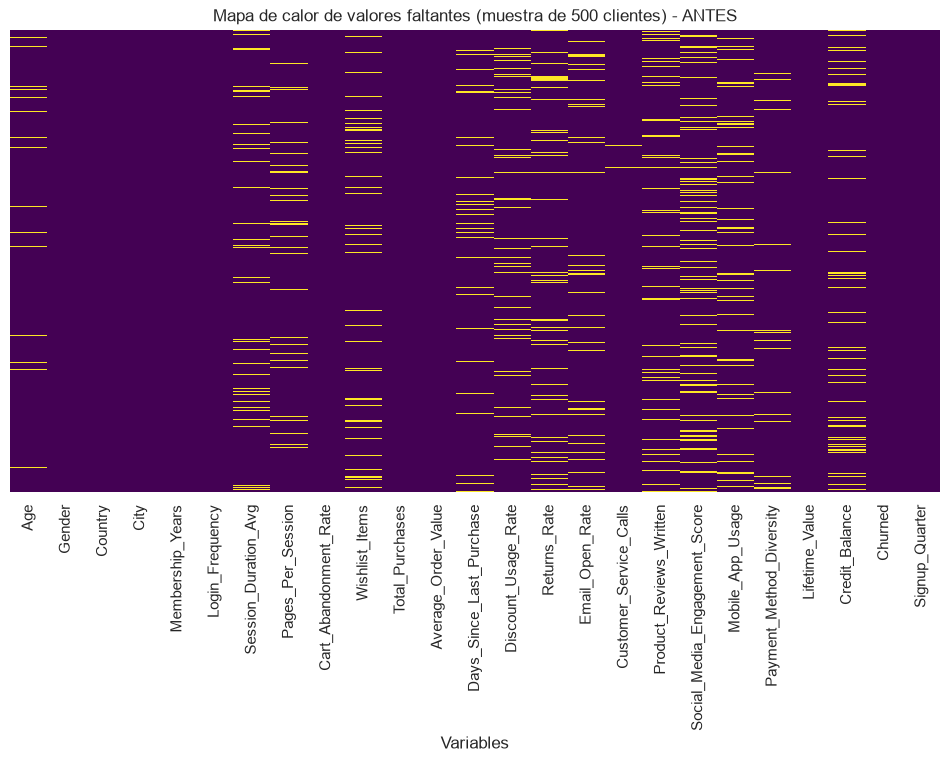

In [217]:
# Se toma una muestra de 500 clientes para que el mapa de calor sea legible
muestra = datos.sample(500, random_state=42)

plt.figure(figsize=(12, 6))
sns.heatmap(muestra.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de calor de valores faltantes (muestra de 500 clientes) - ANTES")
plt.xlabel("Variables")
plt.show()

### 2.2 Decisión: ¿eliminar o imputar?

- **No eliminamos filas:** el **64 %** de los clientes tiene al menos un dato faltante. Si usáramos `dropna()` perderíamos más de la mitad de la base de datos.
- **No eliminamos columnas:** ninguna variable supera el **12 %** de faltantes, por lo que todas conservan información útil.
- **Imputamos con la mediana:** varias variables tienen valores extremos (ej. `Age` y `Average_Order_Value`), y la mediana **no se ve afectada por los outliers**, a diferencia de la media.
- En las variables **discretas** (conteos), la mediana se redondea para que el valor imputado siga siendo un número entero.
- Las variables categóricas **no tienen faltantes**, así que no requieren imputación.

In [218]:
columnas_con_nulos = datos.columns[datos.isnull().any()]

for columna in columnas_con_nulos:
    mediana = datos[columna].median()
    if columna in discretas:
        mediana = round(mediana)
    datos[columna] = datos[columna].fillna(mediana)
    print(f"{columna}: faltantes imputados con la mediana = {mediana}")

Age: faltantes imputados con la mediana = 38.0
Session_Duration_Avg: faltantes imputados con la mediana = 26.8
Pages_Per_Session: faltantes imputados con la mediana = 8.4
Wishlist_Items: faltantes imputados con la mediana = 4
Days_Since_Last_Purchase: faltantes imputados con la mediana = 21
Discount_Usage_Rate: faltantes imputados con la mediana = 40.2
Returns_Rate: faltantes imputados con la mediana = 5.4
Email_Open_Rate: faltantes imputados con la mediana = 19.7
Customer_Service_Calls: faltantes imputados con la mediana = 5
Product_Reviews_Written: faltantes imputados con la mediana = 2
Social_Media_Engagement_Score: faltantes imputados con la mediana = 27.6
Mobile_App_Usage: faltantes imputados con la mediana = 18.6
Payment_Method_Diversity: faltantes imputados con la mediana = 2
Credit_Balance: faltantes imputados con la mediana = 1896.0


### 2.3 Mapa de calor de valores faltantes (después)

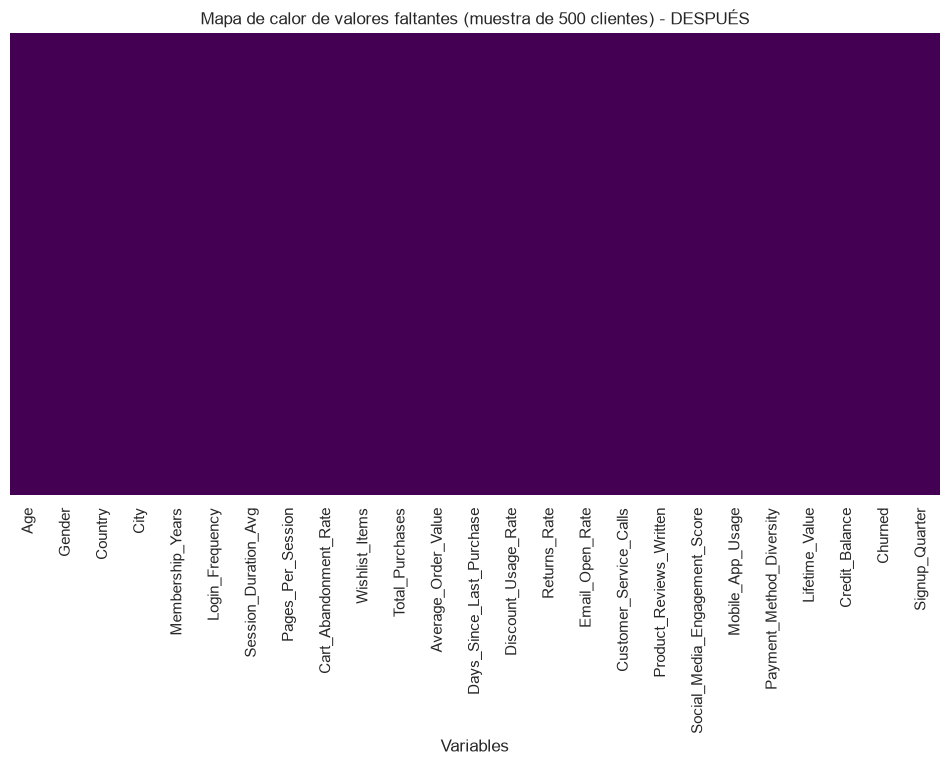

Total de valores faltantes después de la imputación: 0


In [219]:
plt.figure(figsize=(12, 6))
sns.heatmap(datos.sample(500, random_state=42).isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de calor de valores faltantes (muestra de 500 clientes) - DESPUÉS")
plt.xlabel("Variables")
plt.show()

print(f"Total de valores faltantes después de la imputación: {datos.isnull().sum().sum()}")

> **Conclusión:** Se imputaron los faltantes de 14 variables con su mediana. El mapa de calor ya no muestra espacios vacíos y la base conserva los **50.000 clientes**, lo que permite analizar a todos los clientes sin perder información.

---
## 3. Identificación de outliers

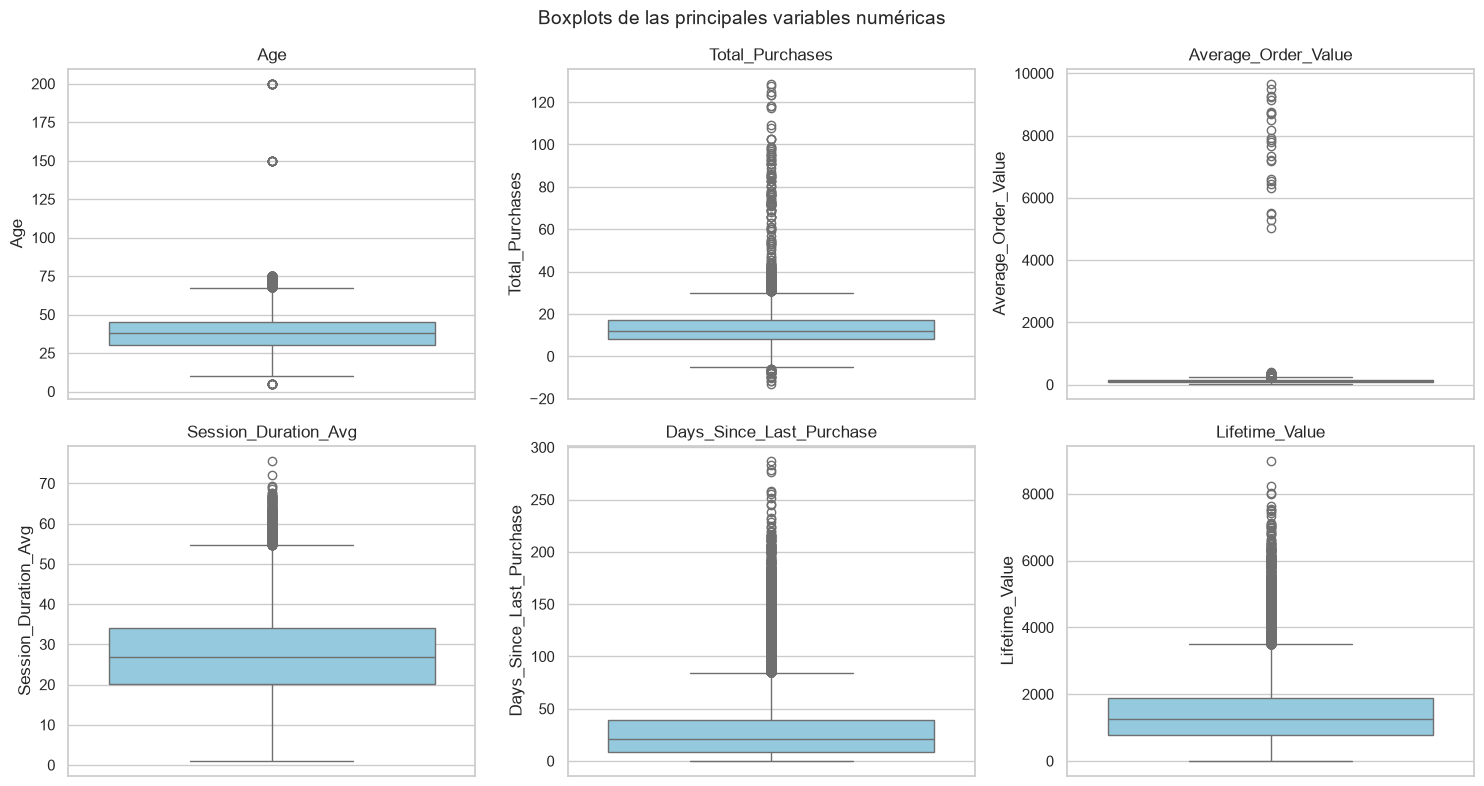

In [220]:
variables_outliers = ["Age", "Total_Purchases", "Average_Order_Value",
                      "Session_Duration_Avg", "Days_Since_Last_Purchase", "Lifetime_Value"]

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for eje, variable in zip(ejes.flatten(), variables_outliers):
    sns.boxplot(y=datos[variable], ax=eje, color="skyblue")
    eje.set_title(variable)
plt.suptitle("Boxplots de las principales variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

Contamos cuántos outliers tiene cada variable usando el **rango intercuartílico (IQR)**: un valor es atípico si está por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR.

In [221]:
resumen = []
for variable in variables_outliers:
    q1 = datos[variable].quantile(0.25)
    q3 = datos[variable].quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    n_outliers = ((datos[variable] < limite_inf) | (datos[variable] > limite_sup)).sum()
    resumen.append([variable, round(limite_inf, 2), round(limite_sup, 2), n_outliers])

pd.DataFrame(resumen, columns=["Variable", "Límite inferior", "Límite superior", "N° outliers"])

,Variable,Límite inferior,Límite superior,N° outliers
0,Age,7.50,67.50,321
1,Total_Purchases,-5.50,30.50,628
2,Average_Order_Value,0.96,230.52,1005
3,Session_Duration_Avg,-0.50,54.70,529
4,Days_Since_Last_Purchase,-36.00,84.00,2727
5,Lifetime_Value,-836.46,3500.27,1684


### 3.1 Tratamiento de outliers

No todos los outliers se tratan igual. Diferenciamos entre **errores** y **clientes reales con valores altos**:

| Variable | Decisión | Justificación |
|---|---|---|
| `Age` | Reemplazar edades < 18 o > 100 por la mediana | Edades de 5 o 200 años son **errores de registro**; un cliente de comercio electrónico debe ser mayor de edad. |
| `Average_Order_Value` y `Total_Purchases` | Limitar (*capping*) al percentil 99 | Hay pocos valores muy extremos (ej. pedido promedio de 9.666 frente a una mediana de 113) que distorsionan los promedios. Se conservan los clientes, pero se recorta su valor extremo. |
| `Session_Duration_Avg`, `Days_Since_Last_Purchase`, `Lifetime_Value` | Conservar | Son valores **posibles** (clientes muy activos, inactivos o de mucho valor) y son justamente los que queremos estudiar en el análisis de fidelización. |

In [222]:
# Edad: errores de registro
mediana_edad = datos["Age"].median()
errores_edad = ((datos["Age"] < 18) | (datos["Age"] > 100)).sum()
datos.loc[(datos["Age"] < 18) | (datos["Age"] > 100), "Age"] = mediana_edad
print(f"Edades imposibles corregidas: {errores_edad} (reemplazadas por la mediana = {mediana_edad})")

# Capping en el percentil 99
for variable in ["Average_Order_Value", "Total_Purchases"]:
    p99 = datos[variable].quantile(0.99)
    n = (datos[variable] > p99).sum()
    datos[variable] = datos[variable].clip(upper=p99)
    print(f"{variable}: {n} valores limitados al percentil 99 = {p99:.2f}")

Edades imposibles corregidas: 50 (reemplazadas por la mediana = 38.0)
Average_Order_Value: 500 valores limitados al percentil 99 = 252.30
Total_Purchases: 452 valores limitados al percentil 99 = 31.20


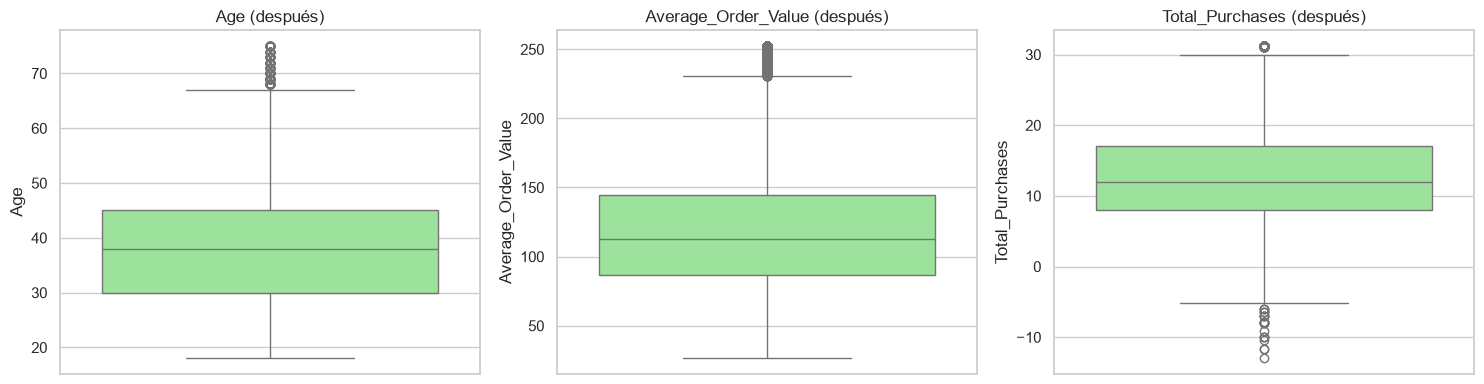

In [223]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, variable in zip(ejes, ["Age", "Average_Order_Value", "Total_Purchases"]):
    sns.boxplot(y=datos[variable], ax=eje, color="lightgreen")
    eje.set_title(f"{variable} (después)")
plt.tight_layout()
plt.show()

> **Conclusión:** Después del tratamiento, la edad queda entre 18 y 75 años y el valor promedio del pedido ya no tiene valores de miles. Las demás variables conservan sus valores altos porque representan comportamientos reales de los clientes.

---
## 4. Tratamiento de valores inconsistentes en texto y duplicados

### 4.1 Inconsistencias en variables de texto

In [224]:
columnas_texto = ["Gender", "Country", "City", "Signup_Quarter"]

for columna in columnas_texto:
    print(f"{columna}: {datos[columna].nunique()} valores únicos")
    print(sorted(datos[columna].unique()), "\n")

Gender: 3 valores únicos
['Female', 'Male', 'Other'] 

Country: 8 valores únicos
['Australia', 'Canada', 'France', 'Germany', 'India', 'Japan', 'UK', 'USA'] 

City: 40 valores únicos
['Adelaide', 'Bangalore', 'Berlin', 'Birmingham', 'Brisbane', 'Calgary', 'Chennai', 'Chicago', 'Cologne', 'Delhi', 'Frankfurt', 'Glasgow', 'Hamburg', 'Houston', 'Hyderabad', 'Kyoto', 'Leeds', 'London', 'Los Angeles', 'Lyon', 'Manchester', 'Marseille', 'Melbourne', 'Montreal', 'Mumbai', 'Munich', 'Nagoya', 'New York', 'Nice', 'Osaka', 'Ottawa', 'Paris', 'Perth', 'Phoenix', 'Sydney', 'Tokyo', 'Toronto', 'Toulouse', 'Vancouver', 'Yokohama'] 

Signup_Quarter: 4 valores únicos
['Q1', 'Q2', 'Q3', 'Q4'] 



Como medida preventiva, estandarizamos el texto: quitamos espacios al inicio y al final (`strip`) y dejamos la primera letra en mayúscula (`title`). Luego verificamos que la cantidad de categorías no cambie.

In [225]:
for columna in ["Gender", "Country", "City"]:
    antes = datos[columna].nunique()
    datos[columna] = datos[columna].str.strip().str.title()
    datos[columna] = datos[columna].replace({"Usa": "USA", "Uk": "UK"})  # siglas en mayúscula
    despues = datos[columna].nunique()
    print(f"{columna}: {antes} categorías antes -> {despues} categorías después")

datos["Signup_Quarter"] = datos["Signup_Quarter"].str.strip().str.upper()

Gender: 3 categorías antes -> 3 categorías después
Country: 8 categorías antes -> 8 categorías después
City: 40 categorías antes -> 40 categorías después


> **Conclusión:** Las variables de texto **no presentaban inconsistencias** (no hay mayúsculas mezcladas, espacios extra ni abreviaturas distintas para la misma categoría). La cantidad de categorías se mantuvo igual después de estandarizar.

### 4.2 Valores numéricos inconsistentes

In [226]:
print("Compras negativas:", (datos["Total_Purchases"] < 0).sum())
print("Compras con decimales:", (datos["Total_Purchases"] % 1 != 0).sum())
for columna in ["Cart_Abandonment_Rate", "Discount_Usage_Rate", "Returns_Rate"]:
    print(f"{columna} mayor a 100 %:", (datos[columna] > 100).sum())

Compras negativas: 40
Compras con decimales: 11391
Cart_Abandonment_Rate mayor a 100 %: 30
Discount_Usage_Rate mayor a 100 %: 207
Returns_Rate mayor a 100 %: 0


- Un cliente **no puede tener compras negativas** → se reemplazan por la mediana.
- El número de compras es un **conteo** → se redondea a entero.
- Un **porcentaje no puede superar el 100 %** → se limita al rango 0–100.

In [227]:
datos.loc[datos["Total_Purchases"] < 0, "Total_Purchases"] = datos["Total_Purchases"].median()
datos["Total_Purchases"] = datos["Total_Purchases"].round()

for columna in ["Cart_Abandonment_Rate", "Discount_Usage_Rate", "Returns_Rate"]:
    datos[columna] = datos[columna].clip(lower=0, upper=100)

# Ahora que no hay faltantes, las variables discretas pueden ser enteros
for columna in discretas:
    datos[columna] = datos[columna].round().astype(int)

print("Compras negativas:", (datos["Total_Purchases"] < 0).sum())
print("Porcentajes mayores a 100:", (datos[["Cart_Abandonment_Rate", "Discount_Usage_Rate", "Returns_Rate"]] > 100).sum().sum())

Compras negativas: 0
Porcentajes mayores a 100: 0


### 4.3 Registros duplicados

In [228]:
duplicados = datos.duplicated().sum()
print(f"Registros duplicados: {duplicados}")

datos = datos.drop_duplicates()
print(f"Registros después de eliminar duplicados: {len(datos)}")

Registros duplicados: 0
Registros después de eliminar duplicados: 50000


> **Conclusión:** No se encontraron registros duplicados, por lo que se conservan los 50.000 clientes. Sí se corrigieron **40 compras negativas**, más de **11.000 compras con decimales** y **237 porcentajes mayores a 100 %**, que eran valores imposibles.

---
## 5. Creación de variables

Creamos 4 variables nuevas a partir de las existentes:

| Nueva variable | Se crea a partir de | Para qué sirve |
|---|---|---|
| `Nivel_Engagement` | `Login_Frequency` | Clasificar qué tan activo es el cliente |
| `Nivel_Valor_Cliente` | `Lifetime_Value` | Clasificar cuánto valor ha generado el cliente |
| `Grupo_Edad` | `Age` | Comparar clientes por rango de edad |
| `Estado_Cliente` | `Churned`, `Days_Since_Last_Purchase`, `Login_Frequency` | Identificar clientes activos, en riesgo y perdidos |

**1. `Nivel_Engagement`**
- Bajo: 0 a 5 inicios de sesión
- Medio: 6 a 12
- Alto: 13 a 20
- Muy alto: más de 20

In [229]:
datos["Nivel_Engagement"] = pd.cut(datos["Login_Frequency"],
                                   bins=[-1, 5, 12, 20, np.inf],
                                   labels=["Bajo", "Medio", "Alto", "Muy alto"])
datos["Nivel_Engagement"].value_counts().sort_index()

Nivel_Engagement
Bajo        12191
Medio       16543
Alto        14376
Muy alto     6890
Name: count, dtype: int64

**2. `Nivel_Valor_Cliente`**: dividimos a los clientes en 4 grupos del mismo tamaño (cuartiles) según su `Lifetime_Value`: Bajo, Medio, Alto y Premium.

In [230]:
datos["Nivel_Valor_Cliente"] = pd.qcut(datos["Lifetime_Value"], q=4,
                                      labels=["Bajo", "Medio", "Alto", "Premium"])
datos.groupby("Nivel_Valor_Cliente", observed=True)["Lifetime_Value"].agg(["min", "max", "count"]).round(2)

,min,max,count
Nivel_Valor_Cliente,,,
Bajo,0.00,789.81,12500
Medio,789.82,1243.39,12500
Alto,1243.44,1873.98,12500
Premium,1874.06,8987.24,12500


**3. `Grupo_Edad`**

In [231]:
datos["Grupo_Edad"] = pd.cut(datos["Age"], bins=[17, 25, 35, 50, 65, 100],
                             labels=["18-25", "26-35", "36-50", "51-65", "66+"])
datos["Grupo_Edad"].value_counts().sort_index()

Grupo_Edad
18-25     7511
26-35    13049
36-50    22793
51-65     6189
66+        458
Name: count, dtype: int64

**4. `Estado_Cliente`**
- **Perdido:** el cliente ya abandonó (`Churned` = 1).
- **En riesgo:** no ha abandonado, pero lleva más de 60 días sin comprar o inicia sesión 5 veces o menos.
- **Activo:** el resto de clientes.

In [232]:
def clasificar_estado(fila):
    if fila["Churned"] == 1:
        return "Perdido"
    elif fila["Days_Since_Last_Purchase"] > 60 or fila["Login_Frequency"] <= 5:
        return "En riesgo"
    else:
        return "Activo"

datos["Estado_Cliente"] = datos.apply(clasificar_estado, axis=1)
datos["Estado_Cliente"].value_counts()

Estado_Cliente
Activo       25819
Perdido      14450
En riesgo     9731
Name: count, dtype: int64

In [233]:
datos[["Login_Frequency", "Nivel_Engagement", "Lifetime_Value", "Nivel_Valor_Cliente",
       "Age", "Grupo_Edad", "Estado_Cliente"]].head()

,Login_Frequency,Nivel_Engagement,Lifetime_Value,Nivel_Valor_Cliente,Age,Grupo_Edad,Estado_Cliente
0,14,Alto,953.33,Medio,43.0,36-50,Activo
1,15,Alto,1067.47,Medio,36.0,36-50,En riesgo
2,10,Medio,1289.75,Alto,45.0,36-50,Activo
3,10,Medio,2340.92,Premium,56.0,51-65,Activo
4,29,Muy alto,3041.29,Premium,35.0,26-35,En riesgo


> **Conclusión:** Con las nuevas variables, **9.731 clientes** quedan clasificados como **"En riesgo"**: todavía no han abandonado, pero muestran señales de alejamiento. Son el grupo en el que la empresa debería enfocar sus campañas de retención.

---
## 6. Filtrado y condiciones con Pandas

Recordemos que la tasa de abandono general es **28,9 %**. En cada filtro la comparamos con esa referencia.

In [234]:
tasa_general = datos["Churned"].mean() * 100
print(f"Tasa de abandono general: {tasa_general:.1f} %")

Tasa de abandono general: 28.9 %


### Filtro 1: ¿Cuántos clientes entran poco a la plataforma (≤ 5 inicios de sesión) y además han llamado 7 o más veces a servicio al cliente? ¿Cuántos abandonan?

In [235]:
filtro1 = datos[(datos["Login_Frequency"] <= 5) & (datos["Customer_Service_Calls"] >= 7)]
print(f"Clientes: {len(filtro1)}")
print(f"Tasa de abandono: {filtro1['Churned'].mean() * 100:.1f} %")

Clientes: 6382
Tasa de abandono: 53.6 %


> **Conclusión:** Hay 6.382 clientes con poca actividad y muchos contactos con soporte, y **el 53,6 % abandonó**: casi el doble de la tasa general. Pocas visitas combinadas con problemas frecuentes son una señal fuerte de abandono.

### Filtro 2: ¿Cuántos clientes de alto valor (Lifetime Value en el 25 % superior) abandonaron la plataforma?

In [236]:
p75_valor = datos["Lifetime_Value"].quantile(0.75)
alto_valor = datos[datos["Lifetime_Value"] > p75_valor]
filtro2 = alto_valor[alto_valor["Churned"] == 1]

print(f"Umbral de alto valor (percentil 75): {p75_valor:.2f}")
print(f"Clientes de alto valor que abandonaron: {len(filtro2)} de {len(alto_valor)} ({len(filtro2) / len(alto_valor) * 100:.1f} %)")
print(f"Valor generado por esos clientes perdidos: {filtro2['Lifetime_Value'].sum():,.0f}")

Umbral de alto valor (percentil 75): 1874.00
Clientes de alto valor que abandonaron: 4956 de 12500 (39.6 %)
Valor generado por esos clientes perdidos: 12,904,219


> **Conclusión:** El **39,6 %** de los clientes de mayor valor abandonó, una tasa más alta que la general. Esto es preocupante, porque la empresa está perdiendo justamente a quienes más dinero le han generado (más de 12 millones en valor acumulado).

### Filtro 3: ¿Cuántos clientes siguen activos pero llevan más de 60 días sin comprar?

In [237]:
filtro3 = datos[(datos["Days_Since_Last_Purchase"] > 60) & (datos["Churned"] == 0)]
print(f"Clientes que no han abandonado pero llevan más de 60 días sin comprar: {len(filtro3)}")
print(f"Lifetime Value promedio de este grupo: {filtro3['Lifetime_Value'].mean():.2f}")

Clientes que no han abandonado pero llevan más de 60 días sin comprar: 3466
Lifetime Value promedio de este grupo: 1606.11


> **Conclusión:** 3.466 clientes no han abandonado formalmente pero llevan más de dos meses sin comprar, y tienen un valor promedio de 1.606 (mayor al promedio general de 1.441). Son clientes valiosos a los que conviene enviar campañas de reactivación antes de que se pierdan.

### Filtro 4: ¿Cuántos clientes son muy comprometidos (20 o más inicios de sesión y sesiones de 35 minutos o más)? ¿Cuántos abandonan?

In [238]:
filtro4 = datos[(datos["Login_Frequency"] >= 20) & (datos["Session_Duration_Avg"] >= 35)]
print(f"Clientes muy comprometidos: {len(filtro4)}")
print(f"Tasa de abandono: {filtro4['Churned'].mean() * 100:.1f} %")

Clientes muy comprometidos: 5842
Tasa de abandono: 17.7 %


> **Conclusión:** Los 5.842 clientes más comprometidos abandonan solo en un **17,7 %**, 11 puntos menos que el promedio. Que el cliente entre seguido y se quede más tiempo en cada visita está asociado a una mayor permanencia.

### Filtro 5: ¿Qué pasa con los clientes que abandonan más del 70 % de sus carritos y abren menos del 10 % de los correos?

In [239]:
filtro5 = datos[(datos["Cart_Abandonment_Rate"] > 70) & (datos["Email_Open_Rate"] < 10)]
print(f"Clientes: {len(filtro5)}")
print(f"Tasa de abandono: {filtro5['Churned'].mean() * 100:.1f} %")

Clientes: 5048
Tasa de abandono: 69.8 %


> **Conclusión:** De los 5.048 clientes que casi nunca terminan sus compras y no leen los correos, **el 69,8 % abandonó**, más del doble de la tasa general. Es el grupo con mayor riesgo encontrado en el análisis.

---
## 7. Agrupación con `groupby`

### Agrupación 1: Tasa de abandono y valor del cliente según el nivel de engagement

In [240]:
g1 = datos.groupby("Nivel_Engagement", observed=True).agg(
    Clientes=("Churned", "size"),
    Tasa_Abandono=("Churned", "mean"),
    Sesion_Promedio_min=("Session_Duration_Avg", "mean"),
    Valor_Promedio=("Lifetime_Value", "mean")
)
g1["Tasa_Abandono"] = g1["Tasa_Abandono"] * 100
g1.round(1)

,Clientes,Tasa_Abandono,Sesion_Promedio_min,Valor_Promedio
Nivel_Engagement,,,,
Bajo,12191,45.4,19.7,931.9
Medio,16543,27.3,24.6,1260.3
Alto,14376,21.8,31.2,1680.7
Muy alto,6890,18.1,41.2,2272.9


> **Conclusión:** A mayor engagement, menor abandono: pasa de **45,4 %** en el nivel Bajo a **18,1 %** en el nivel Muy alto. Además, los clientes más activos generan más del doble de valor (2.273 frente a 932).

### Agrupación 2: Perfil de los clientes según su nivel de valor

In [241]:
g2 = datos.groupby("Nivel_Valor_Cliente", observed=True).agg(
    Tasa_Abandono=("Churned", "mean"),
    Compras_Promedio=("Total_Purchases", "mean"),
    Pedido_Promedio=("Average_Order_Value", "mean"),
    Logins_Promedio=("Login_Frequency", "mean"),
    Llamadas_Soporte=("Customer_Service_Calls", "mean")
)
g2["Tasa_Abandono"] = g2["Tasa_Abandono"] * 100
g2.round(1)

,Tasa_Abandono,Compras_Promedio,Pedido_Promedio,Logins_Promedio,Llamadas_Soporte
Nivel_Valor_Cliente,,,,,
Bajo,41.3,7.2,91.8,6.4,6.7
Medio,20.3,11.4,107.3,10.0,6.0
Alto,14.4,14.6,122.7,13.0,5.4
Premium,39.6,18.8,154.9,17.0,4.6


> **Conclusión:** La relación entre valor y abandono tiene forma de **U**: los clientes de valor Bajo (41 %) y Premium (40 %) son los que más abandonan, mientras que los de valor Alto son los más fieles (14,4 %). Los Premium compran más y hacen pedidos más grandes, pero aun así se van, lo que sugiere que la empresa no les está ofreciendo beneficios suficientes para retenerlos.

### Agrupación 3: Tasa de abandono según la cantidad de contactos con servicio al cliente

In [242]:
datos_temp = datos.copy()
datos_temp["Rango_Llamadas"] = pd.cut(datos_temp["Customer_Service_Calls"],
                                      bins=[-1, 3, 5, 9, 100],
                                      labels=["0-3", "4-5", "6-9", "10 o más"])

g3 = datos_temp.groupby("Rango_Llamadas", observed=True)["Churned"].agg(["size", "mean"])
g3.columns = ["Clientes", "Tasa_Abandono"]
g3["Tasa_Abandono"] = g3["Tasa_Abandono"] * 100
g3.round(1)

,Clientes,Tasa_Abandono
Rango_Llamadas,,
0-3,10890,12.5
4-5,14330,17.3
6-9,20529,41.2
10 o más,4251,50.8


> **Conclusión:** Los clientes que contactan a servicio al cliente 3 veces o menos abandonan en un **12,5 %**, mientras que los que lo hacen 10 veces o más abandonan en un **50,8 %**. Necesitar soporte con frecuencia indica problemas que terminan alejando al cliente.

### Agrupación 4: Tasa de abandono y valor promedio por país

In [243]:
g4 = datos.groupby("Country").agg(
    Clientes=("Churned", "size"),
    Tasa_Abandono=("Churned", "mean"),
    Valor_Promedio=("Lifetime_Value", "mean")
).sort_values("Tasa_Abandono", ascending=False)
g4["Tasa_Abandono"] = g4["Tasa_Abandono"] * 100
g4.round(1)

,Clientes,Tasa_Abandono,Valor_Promedio
Country,,,
Australia,4061,29.9,1443.2
Canada,6023,29.4,1427.2
USA,17384,29.1,1435.9
India,3512,29.0,1458.1
Germany,4925,28.8,1447.7
UK,7534,28.8,1436.7
Japan,2548,27.8,1457.0
France,4013,27.3,1451.5


> **Conclusión:** Estados Unidos concentra el 35 % de los clientes, pero la tasa de abandono es muy parecida en todos los países (entre 27,3 % y 29,9 %). Esto indica que el abandono **no depende de la ubicación geográfica**, sino del comportamiento del cliente dentro de la plataforma.

### Agrupación 5: Comparación del comportamiento entre clientes que permanecen y clientes que abandonan

In [244]:
variables_comparar = ["Login_Frequency", "Session_Duration_Avg", "Pages_Per_Session",
                      "Cart_Abandonment_Rate", "Email_Open_Rate", "Customer_Service_Calls",
                      "Days_Since_Last_Purchase", "Age"]

g5 = datos.groupby("Churned")[variables_comparar].mean().T
g5.columns = ["Permanece (0)", "Abandonó (1)"]
g5["Diferencia"] = g5["Abandonó (1)"] - g5["Permanece (0)"]
g5.round(2)

,Permanece (0),Abandonó (1),Diferencia
Login_Frequency,12.64,9.12,-3.52
Session_Duration_Avg,29.07,23.99,-5.08
Pages_Per_Session,9.24,7.43,-1.82
Cart_Abandonment_Rate,54.18,64.17,9.99
Email_Open_Rate,22.79,16.16,-6.63
Customer_Service_Calls,5.18,6.90,1.71
Days_Since_Last_Purchase,26.54,35.97,9.43
Age,38.50,35.99,-2.51


> **Conclusión:** Los clientes que abandonaron inician menos sesión (9,1 vs 12,6), sus sesiones son 5 minutos más cortas, abandonan más carritos (64 % vs 54 %), abren menos correos, llaman más a soporte y llevan 9 días más sin comprar. El cliente que se va muestra **señales de desinterés antes de irse**.

---
## 8. Visualizaciones

### Gráfico 1: Distribución de clientes que permanecen vs. abandonan

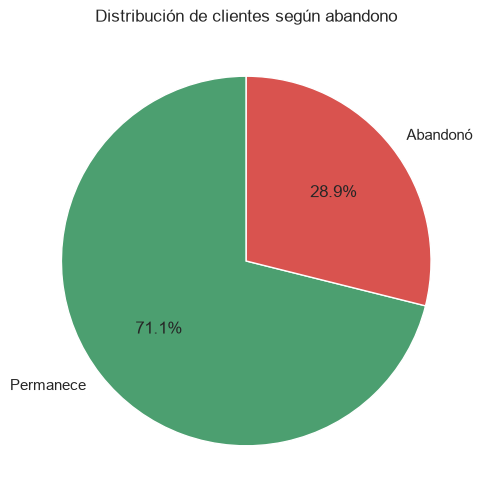

In [245]:
conteo = datos["Churned"].map({0: "Permanece", 1: "Abandonó"}).value_counts()

plt.figure(figsize=(6, 6))
plt.pie(conteo, labels=conteo.index, autopct="%1.1f%%", colors=["#4C9F70", "#D9534F"], startangle=90)
plt.title("Distribución de clientes según abandono")
plt.show()

> **Conclusión:** Casi **3 de cada 10 clientes** abandonaron la plataforma. Es una proporción alta que justifica analizar las causas del abandono.

### Gráfico 2: Tasa de abandono según el nivel de engagement

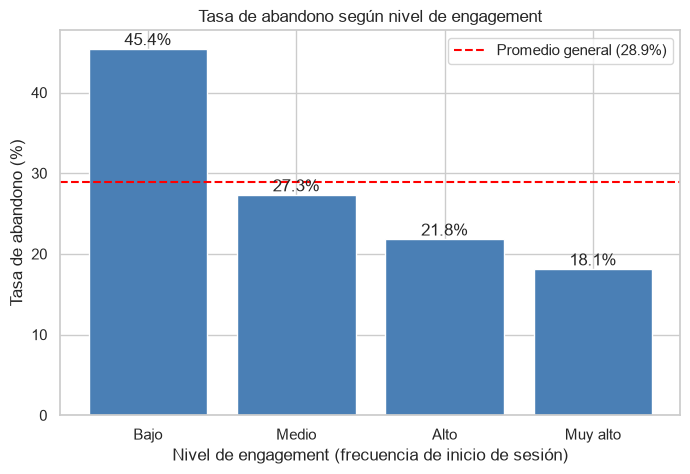

In [246]:
tasa_engagement = datos.groupby("Nivel_Engagement", observed=True)["Churned"].mean() * 100

plt.figure(figsize=(8, 5))
barras = plt.bar(tasa_engagement.index.astype(str), tasa_engagement.values, color="#4A7FB5")
plt.bar_label(barras, fmt="%.1f%%")
plt.axhline(tasa_general, color="red", linestyle="--", label=f"Promedio general ({tasa_general:.1f}%)")
plt.title("Tasa de abandono según nivel de engagement")
plt.xlabel("Nivel de engagement (frecuencia de inicio de sesión)")
plt.ylabel("Tasa de abandono (%)")
plt.legend()
plt.show()

> **Conclusión:** La tasa de abandono baja de forma constante a medida que aumenta el engagement. Los clientes de engagement **Bajo** son los únicos que superan con amplitud el promedio general.

### Gráfico 3: Tasa de abandono según contactos con servicio al cliente

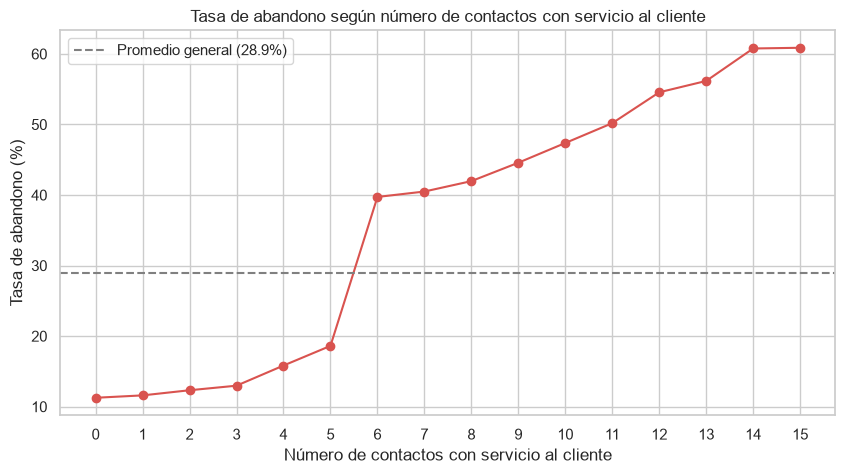

In [247]:
tasa_llamadas = datos[datos["Customer_Service_Calls"] <= 15].groupby("Customer_Service_Calls")["Churned"].mean() * 100

plt.figure(figsize=(10, 5))
plt.plot(tasa_llamadas.index, tasa_llamadas.values, marker="o", color="#D9534F")
plt.axhline(tasa_general, color="gray", linestyle="--", label=f"Promedio general ({tasa_general:.1f}%)")
plt.title("Tasa de abandono según número de contactos con servicio al cliente")
plt.xlabel("Número de contactos con servicio al cliente")
plt.ylabel("Tasa de abandono (%)")
plt.xticks(range(0, 16))
plt.legend()
plt.show()

> **Conclusión:** Hay un **salto fuerte entre 5 y 6 contactos**: la tasa de abandono pasa de 18,6 % a 39,7 %. A partir del sexto contacto con soporte, el riesgo de perder al cliente se duplica. (Se muestran hasta 15 contactos porque por encima hay muy pocos clientes.)

### Gráfico 4: Duración de las sesiones según abandono

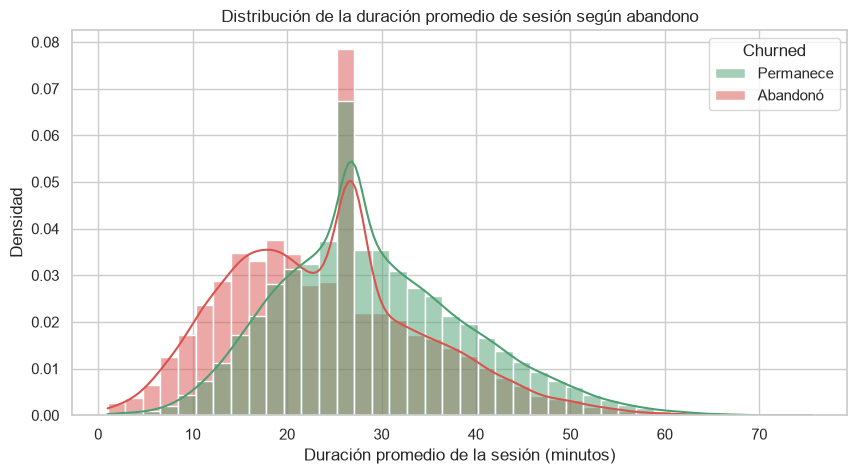

In [248]:
plt.figure(figsize=(10, 5))
sns.histplot(data=datos, x="Session_Duration_Avg",
             hue=datos["Churned"].map({0: "Permanece", 1: "Abandonó"}),
             kde=True, stat="density", common_norm=False, bins=40,
             palette={"Permanece": "#4C9F70", "Abandonó": "#D9534F"})
plt.title("Distribución de la duración promedio de sesión según abandono")
plt.xlabel("Duración promedio de la sesión (minutos)")
plt.ylabel("Densidad")
plt.show()

> **Conclusión:** La curva de los clientes que abandonaron está desplazada hacia la izquierda: sus sesiones son más cortas. Los clientes que permanecen pasan, en promedio, unos 5 minutos más por sesión en la plataforma.

### Gráfico 5: Correlación entre las variables de comportamiento y el abandono

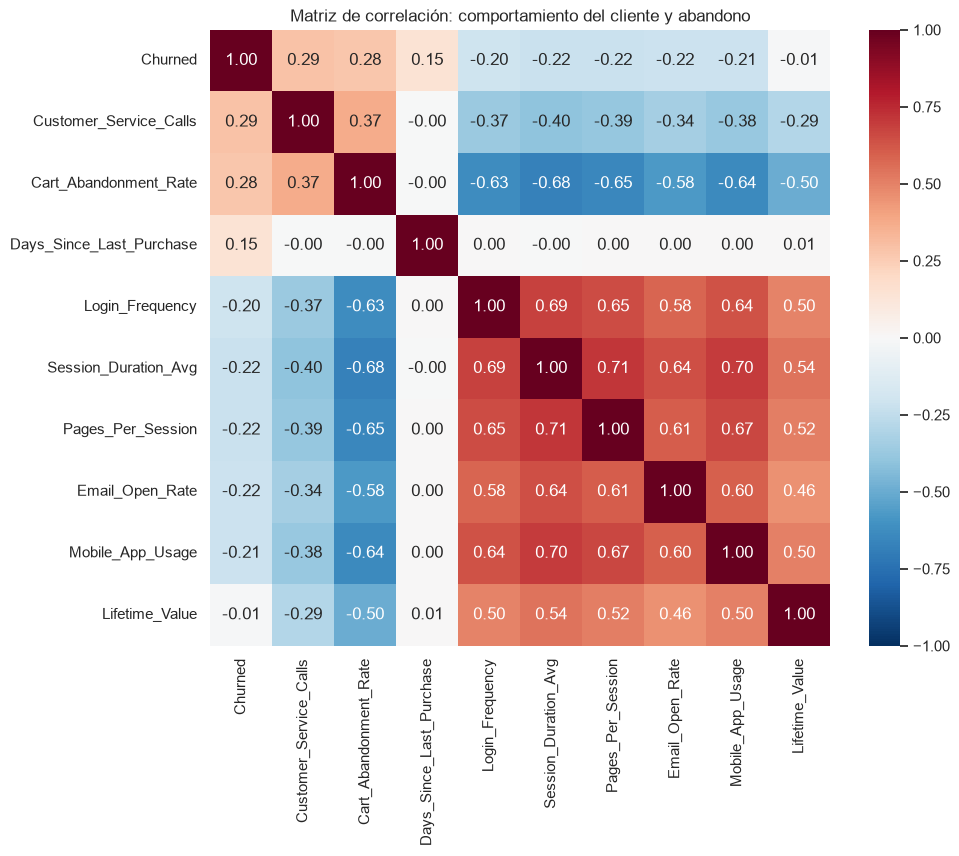

In [249]:
variables_corr = ["Churned", "Customer_Service_Calls", "Cart_Abandonment_Rate", "Days_Since_Last_Purchase",
                  "Login_Frequency", "Session_Duration_Avg", "Pages_Per_Session", "Email_Open_Rate",
                  "Mobile_App_Usage", "Lifetime_Value"]

plt.figure(figsize=(10, 8))
sns.heatmap(datos[variables_corr].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlación: comportamiento del cliente y abandono")
plt.show()

> **Conclusión:** Las variables con mayor relación **positiva** con el abandono son los contactos con servicio al cliente y la tasa de carritos abandonados. Las de relación **negativa** (protegen al cliente) son las páginas por sesión, la duración de la sesión, el uso de la app móvil y la apertura de correos. Ninguna correlación es muy fuerte por sí sola, lo que indica que el abandono depende de **varios factores combinados**.